In [2]:
'''
- Tree Based Algorithm
- Decision Tree
    - Tree Based Learning


- Random Forest
    - Tree Based and Ensemble Learning
    - Extension of Decision Tree

'''


'\n- Tree Based Algorithm\n- Decision Tree\n    - Tree Based Learning\n\n\n- Random Forest\n    - Tree Based and Ensemble Learning\n    - Extension of Decision Tree\n\n'

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Decision Tree
from sklearn.tree import DecisionTreeClassifier
# Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

In [4]:
df = pd.read_csv('Dataset/Fraud Detection Dataset.csv')
df.head()

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,NaN,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0


In [5]:
df.isnull().sum()

Transaction_ID                         0
User_ID                                0
Transaction_Amount                  2520
Transaction_Type                       0
Time_of_Transaction                 2552
Device_Used                         2473
Location                            2547
Previous_Fraudulent_Transactions       0
Account_Age                            0
Number_of_Transactions_Last_24H        0
Payment_Method                      2469
Fraudulent                             0
dtype: int64

In [6]:
# Remove Duplicate data
df.drop_duplicates(subset='Transaction_ID', keep='first', inplace=True)

In [7]:
total_transaction = df['Transaction_ID'].count()
total_transaction

np.int64(50000)

In [8]:
nonFraudulent = df[df['Fraudulent']== 0]['Transaction_ID'].count()
nonFraudulent

np.int64(47540)

In [9]:
Fraudulent = df[df['Fraudulent']== 1]['Transaction_ID'].count()
Fraudulent

np.int64(2460)

In [10]:
df.fillna({'Transaction_Amount':df['Transaction_Amount'].median(),
           'Time_of_Transaction':df['Time_of_Transaction'].mode()[0]}, inplace= True)

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,18.0,Mobile,NaN,3,115,9,NaN,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,T49996,1296,1844.08,Online Purchase,22.0,Desktop,Los Angeles,1,47,4,Credit Card,0
49996,T49997,3592,3274.95,POS Payment,15.0,Mobile,San Francisco,2,81,1,UPI,0
49997,T49998,3536,647.11,Bill Payment,11.0,Unknown Device,Miami,2,96,3,Debit Card,0
49998,T49999,2019,2446.65,POS Payment,9.0,Tablet,Boston,3,117,13,UPI,0


In [11]:
df.fillna({
    'Device_Used': 'Unknown_Device',
    'Location': 'Unknown_Location',
    'Payment_Method': 'Unknown Method'
}, inplace= True)

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Time_of_Transaction,Device_Used,Location,Previous_Fraudulent_Transactions,Account_Age,Number_of_Transactions_Last_24H,Payment_Method,Fraudulent
0,T1,4174,1292.76,ATM Withdrawal,16.0,Tablet,San Francisco,0,119,13,Debit Card,0
1,T2,4507,1554.58,ATM Withdrawal,13.0,Mobile,New York,4,79,3,Credit Card,0
2,T3,1860,2395.02,ATM Withdrawal,18.0,Mobile,Unknown_Location,3,115,9,Unknown Method,0
3,T4,2294,100.10,Bill Payment,15.0,Desktop,Chicago,4,3,4,UPI,0
4,T5,2130,1490.50,POS Payment,19.0,Mobile,San Francisco,2,57,7,Credit Card,0
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,T49996,1296,1844.08,Online Purchase,22.0,Desktop,Los Angeles,1,47,4,Credit Card,0
49996,T49997,3592,3274.95,POS Payment,15.0,Mobile,San Francisco,2,81,1,UPI,0
49997,T49998,3536,647.11,Bill Payment,11.0,Unknown Device,Miami,2,96,3,Debit Card,0
49998,T49999,2019,2446.65,POS Payment,9.0,Tablet,Boston,3,117,13,UPI,0


In [12]:
df.columns

Index(['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type',
       'Time_of_Transaction', 'Device_Used', 'Location',
       'Previous_Fraudulent_Transactions', 'Account_Age',
       'Number_of_Transactions_Last_24H', 'Payment_Method', 'Fraudulent'],
      dtype='str')

In [22]:
columns = ['Transaction_Type','Device_Used', 'Location', 'Payment_Method']
le = LabelEncoder()

for col in columns:
    df[f'{col}_id'] = le.fit_transform(df[col])

### Features and Target

In [20]:
df.columns

Index(['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type',
       'Time_of_Transaction', 'Device_Used', 'Location',
       'Previous_Fraudulent_Transactions', 'Account_Age',
       'Number_of_Transactions_Last_24H', 'Payment_Method', 'Fraudulent',
       'Transaction_Type_id', 'Device_Used_id', 'Location_id',
       'Payment_Method_id'],
      dtype='str')

In [21]:
features = ['Transaction_Amount','Transaction_Type_id','Time_of_Transaction', 'Device_Used_id', 'Location_id','Previous_Fraudulent_Transactions', 'Account_Age',
       'Number_of_Transactions_Last_24H','Payment_Method_id']
target = 'Fraudulent'

In [22]:
X = df[features]
Y = df[target]

### Train TEST SPLIT

In [23]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

### Feature sCALING

In [24]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_TEST_SCALE = scaler.transform(X_test)

### Decision Tree

In [25]:
dt_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42,
    class_weight='balanced'
)
dt_model.fit(X_train_scale, Y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_feat

In [26]:
dt_pred = dt_model.predict(X_TEST_SCALE)

In [27]:
dt_cr = classification_report(Y_test, dt_pred)
dt_cm = confusion_matrix(Y_test, dt_pred)

In [28]:
print(dt_cr)

              precision    recall  f1-score   support

           0       0.95      0.72      0.82      9508
           1       0.05      0.26      0.08       492

    accuracy                           0.69     10000
   macro avg       0.50      0.49      0.45     10000
weighted avg       0.90      0.69      0.78     10000



In [29]:
print(dt_cm)

[[6818 2690]
 [ 365  127]]


<Axes: >

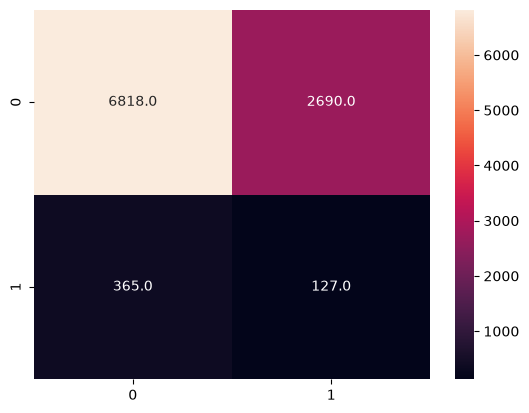

In [30]:
sns.heatmap(dt_cm, annot=True, fmt='1.1f')

### Random Forest Classifier

In [51]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    max_depth=3,
    class_weight='balanced',
    n_jobs=1
)
rf_model.fit(X_train_scale, Y_train)
rf_pred = rf_model.predict(X_TEST_SCALE)

In [52]:
rf_cm = confusion_matrix(Y_test, rf_pred)
rf_cr = classification_report(Y_test, rf_pred)

In [53]:
print(rf_cm)

[[5427 4081]
 [ 277  215]]


In [55]:
print(rf_cr)

              precision    recall  f1-score   support

           0       0.95      0.57      0.71      9508
           1       0.05      0.44      0.09       492

    accuracy                           0.56     10000
   macro avg       0.50      0.50      0.40     10000
weighted avg       0.91      0.56      0.68     10000



<Axes: >

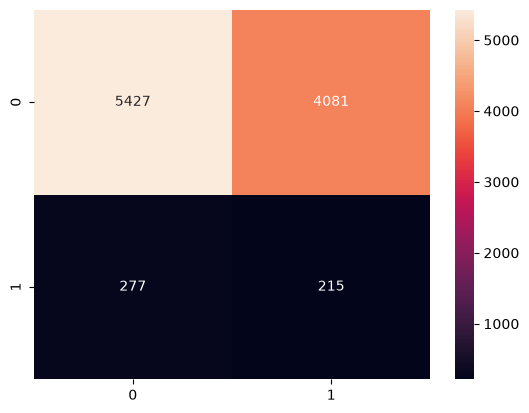

In [57]:
sns.heatmap(rf_cm, annot=True, fmt='1.0f')